In [13]:
from scipy.stats import pearsonr

In [8]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr

# 1. Load your datasets
df_claude = pd.read_csv('AI Evaluation_Claude(Sheet1).csv')
df_gemini = pd.read_csv('AI Evaluation_GPT(Sheet1).csv')

# --- THE FIX: Clean the data before doing any math ---
# Drop rows where 'ID' is missing, and explicitly remove the 'AVG' row
df_claude = df_claude.dropna(subset=['ID'])
df_claude = df_claude[df_claude['ID'] != 'AVG']

df_gemini = df_gemini.dropna(subset=['ID'])
df_gemini = df_gemini[df_gemini['ID'] != 'AVG']
# -----------------------------------------------------

metrics = ['HRO', 'TCF', 'PPA', 'MA', 'SPQ', 'CSDC', 'CER', 'Total']

def calculate_improvement(df, rater_name):
    results = {}
    for m in metrics:
        our_scores = pd.to_numeric(df[f'{m}_Our'], errors='coerce')
        base_scores = pd.to_numeric(df[f'{m}_Base'], errors='coerce')

        abs_improvement = (our_scores - base_scores).mean()

        # Safe relative percentage calculation (ignores zeroes and NaNs)
        valid_mask = (base_scores != 0) & (base_scores.notna())
        rel_improvement = ((our_scores[valid_mask] - base_scores[valid_mask]) / base_scores[valid_mask] * 100).mean()

        results[m] = {
            'Abs_Gain (pts)': round(abs_improvement, 2),
            'Rel_Gain (%)': round(rel_improvement, 2)
        }

    output_df = pd.DataFrame(results).T
    output_df.columns = pd.MultiIndex.from_product([[rater_name], output_df.columns])
    return output_df

def calculate_bias_per_metric(df_claude, df_gemini):
    bias_results = {}
    for m in metrics:
        c_our = pd.to_numeric(df_claude[f'{m}_Our'], errors='coerce')
        g_our = pd.to_numeric(df_gemini[f'{m}_Our'], errors='coerce')
        c_base = pd.to_numeric(df_claude[f'{m}_Base'], errors='coerce')
        g_base = pd.to_numeric(df_gemini[f'{m}_Base'], errors='coerce')

        sys_bias = (g_our - c_our).mean()
        base_bias = (g_base - c_base).mean()

        bias_results[m] = {
            'System_Leniency (+pts)': round(sys_bias, 2),
            'Baseline_Leniency (+pts)': round(base_bias, 2)
        }
    return pd.DataFrame(bias_results).T

def calculate_normalized_irr(df_claude, df_gemini):
    irr_results = {}
    for m in metrics:
        c_all = pd.concat([pd.to_numeric(df_claude[f'{m}_Our'], errors='coerce'),
                           pd.to_numeric(df_claude[f'{m}_Base'], errors='coerce')]).dropna()

        g_all = pd.concat([pd.to_numeric(df_gemini[f'{m}_Our'], errors='coerce'),
                           pd.to_numeric(df_gemini[f'{m}_Base'], errors='coerce')]).dropna()

        c_min, c_max = c_all.min(), c_all.max()
        g_min, g_max = g_all.min(), g_all.max()

        # Failsafe for metrics where every single score was identical
        if c_max == c_min or g_max == g_min:
            irr_results[m] = {'Norm_Pearson_r': np.nan, 'p_value': np.nan}
            continue

        c_norm = (c_all - c_min) / (c_max - c_min)
        g_norm = (g_all - g_min) / (g_max - g_min)

        r, p = pearsonr(c_norm, g_norm)
        irr_results[m] = {
            'Norm_Pearson_r': round(r, 4),
            'p_value': round(p, 4)
        }
    return pd.DataFrame(irr_results).T

def generate_master_summary_table(df_claude, df_gemini):
    df_imp_c = calculate_improvement(df_claude, 'Claude_Evaluation')
    df_imp_g = calculate_improvement(df_gemini, 'Gemini_Evaluation')
    df_bias = calculate_bias_per_metric(df_claude, df_gemini)
    df_irr = calculate_normalized_irr(df_claude, df_gemini)

    df_imp_c.columns = [f"Claude_{col[1]}" for col in df_imp_c.columns]
    df_imp_g.columns = [f"Gemini_{col[1]}" for col in df_imp_g.columns]

    master_table = pd.concat([df_imp_c, df_imp_g, df_bias, df_irr], axis=1)

    print("=" * 110)
    print("MASTER EVALUATION METRICS SUMMARY")
    print("=" * 110)
    return master_table

# Run it
final_table = generate_master_summary_table(df_claude, df_gemini)
print(final_table.to_markdown())

MASTER EVALUATION METRICS SUMMARY
|       |   Claude_Abs_Gain (pts) |   Claude_Rel_Gain (%) |   Gemini_Abs_Gain (pts) |   Gemini_Rel_Gain (%) |   System_Leniency (+pts) |   Baseline_Leniency (+pts) |   Norm_Pearson_r |   p_value |
|:------|------------------------:|----------------------:|------------------------:|----------------------:|-------------------------:|---------------------------:|-----------------:|----------:|
| HRO   |                    6.07 |                 43.61 |                    4.7  |                 26.31 |                     1.27 |                       2.63 |           0.8529 |    0      |
| TCF   |                    2.27 |                 29.2  |                    2.3  |                 23.83 |                     2.07 |                       2.03 |           0.337  |    0.0085 |
| PPA   |                    3.57 |                 38.19 |                    3.27 |                 31.22 |                     1.5  |                       1.8  |           0.

# ICC

In [5]:
# First, you must install pingouin in Colab by running this in a cell:
!pip install pingouin

import pandas as pd
import numpy as np
import pingouin as pg

# 1. Load Data
claude_sys = [89,92,87,75,84,93,85,88,85,84,86,87,92,88,90,95,94,89,91,78,89,86,87,89,91,83,93,88,86,83]
claude_base = [66,63,74,48,67,63,55,70,67,69,64,58,56,69,65,69,67,74,61,60,61,65,71,71,59,62,65,67,62,65]
gpt_sys = [97,88,96,92,94,99,86,87,95,93,97,97,97,100,98,98,95,97,96,97,95,97,93,95,96,97,100,98,96,98]
gpt_base = [74,70,90,63,67,76,67,80,89,71,83,72,70,74,77,87,72,71,74,72,76,77,81,67,72,70,79,67,81,77]

# Combine all 60 scores for each rater
rater_A = np.concatenate([claude_sys, claude_base])
rater_B = np.concatenate([gpt_sys, gpt_base])

# 2. Format data for pingouin (it requires a "long" format dataframe)
data = {
    'Target_ID': np.repeat(np.arange(1, 61), 2),  # 60 unique items evaluated twice
    'Rater': ['Claude', 'Gemini'] * 60,           # Alternating raters
    'Score': np.empty(120)                        # Placeholder for the 120 total scores
}

# Fill the scores by alternating A and B
data['Score'][0::2] = rater_A
data['Score'][1::2] = rater_B

df_icc = pd.DataFrame(data)

# 3. Calculate ICC
icc_results = pg.intraclass_corr(data=df_icc, targets='Target_ID', raters='Rater', ratings='Score')

# Filter the output for exactly what you need
# ICC3 = Two-Way Mixed (Consistency)
# ICC3k = Two-Way Mixed (Absolute Agreement) - note: pingouin handles the exact math for K raters
print("=" * 60)
print("INTRACLASS CORRELATION COEFFICIENT (ICC) REPORT")
print("=" * 60)
print(icc_results[['Type', 'ICC', 'CI95', 'pval']].to_string(index=False))

INTRACLASS CORRELATION COEFFICIENT (ICC) REPORT
    Type      ICC          CI95         pval
ICC(1,1) 0.650646  [0.48, 0.78] 5.589985e-09
ICC(A,1) 0.688890  [-0.07, 0.9] 3.074930e-21
ICC(C,1) 0.882001  [0.81, 0.93] 3.074930e-21
ICC(1,k) 0.788353  [0.65, 0.87] 5.589985e-09
ICC(A,k) 0.815791 [-0.14, 0.95] 3.074930e-21
ICC(C,k) 0.937301   [0.9, 0.96] 3.074930e-21


# ICC with normalized data

In [7]:
import pandas as pd
import numpy as np
import pingouin as pg
from scipy.stats import zscore

# 1. Load Raw Data
claude_sys = np.array([89,92,87,75,84,93,85,88,85,84,86,87,92,88,90,95,94,89,91,78,89,86,87,89,91,83,93,88,86,83])
claude_base = np.array([66,63,74,48,67,63,55,70,67,69,64,58,56,69,65,69,67,74,61,60,61,65,71,71,59,62,65,67,62,65])
gpt_sys = np.array([97,88,96,92,94,99,86,87,95,93,97,97,97,100,98,98,95,97,96,97,95,97,93,95,96,97,100,98,96,98])
gpt_base = np.array([74,70,90,63,67,76,67,80,89,71,83,72,70,74,77,87,72,71,74,72,76,77,81,67,72,70,79,67,81,77])

rater_A_raw = np.concatenate([claude_sys, claude_base])
rater_B_raw = np.concatenate([gpt_sys, gpt_base])

# 2. APPLY Z-SCORE NORMALIZATION
# This forces both raters to have a mean of 0 and standard deviation of 1
rater_A_norm = zscore(rater_A_raw)
rater_B_norm = zscore(rater_B_raw)

# 3. Format normalized data for pingouin
data_norm = {
    'Target_ID': np.repeat(np.arange(1, 61), 2),
    'Rater': ['Claude', 'Gemini'] * 60,
    'Score': np.empty(120)
}
data_norm['Score'][0::2] = rater_A_norm
data_norm['Score'][1::2] = rater_B_norm

df_icc_norm = pd.DataFrame(data_norm)

# 4. Calculate ICC on the NORMALIZED data
icc_norm_results = pg.intraclass_corr(data=df_icc_norm, targets='Target_ID', raters='Rater', ratings='Score')

print("=" * 60)
print("ICC ON Z-SCORE NORMALIZED DATA")
print("=" * 60)
print(icc_norm_results[['Type', 'ICC', 'CI95', 'pval']].to_string(index=False))

ICC ON Z-SCORE NORMALIZED DATA
    Type      ICC         CI95         pval
ICC(1,1) 0.887221 [0.82, 0.93] 4.525212e-22
ICC(A,1) 0.887113 [0.82, 0.93] 1.357937e-21
ICC(C,1) 0.885419 [0.82, 0.93] 1.357937e-21
ICC(1,k) 0.940241  [0.9, 0.96] 4.525212e-22
ICC(A,k) 0.940180  [0.9, 0.96] 1.357937e-21
ICC(C,k) 0.939228  [0.9, 0.96] 1.357937e-21


# **Bland-Altman Plot**

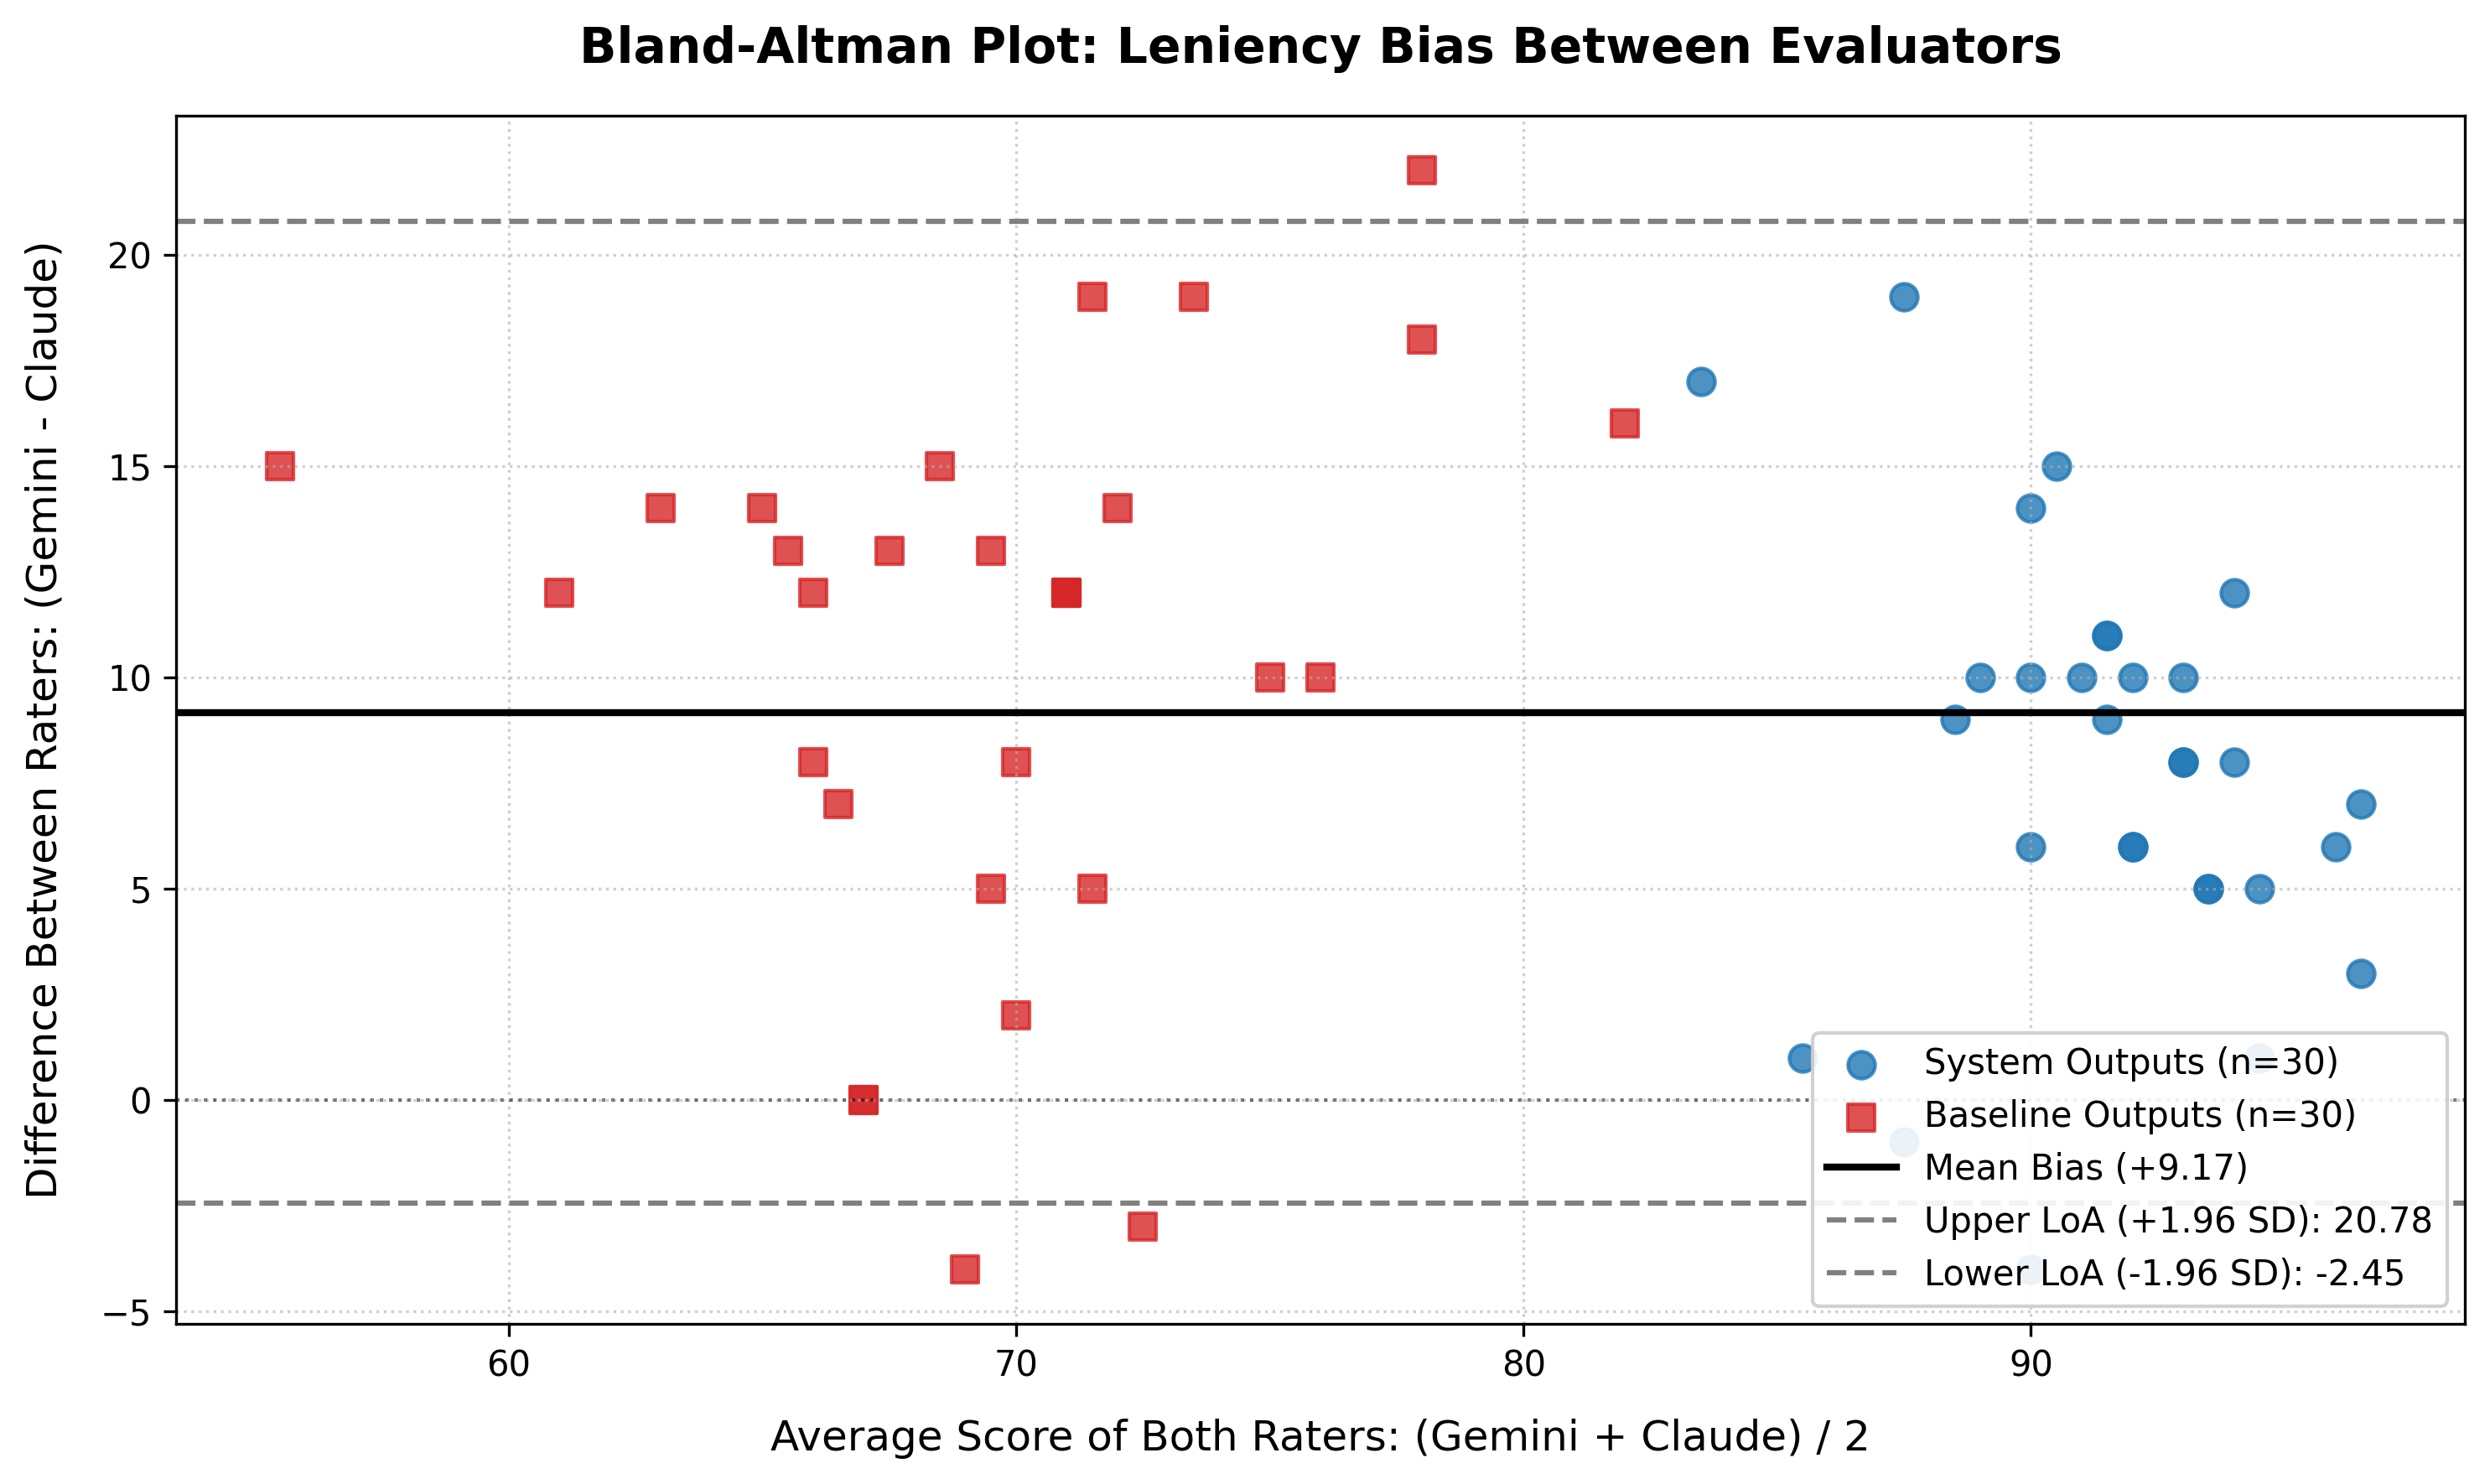

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Your N=30 Dataset
claude_sys = np.array([89,92,87,75,84,93,85,88,85,84,86,87,92,88,90,95,94,89,91,78,89,86,87,89,91,83,93,88,86,83])
claude_base = np.array([66,63,74,48,67,63,55,70,67,69,64,58,56,69,65,69,67,74,61,60,61,65,71,71,59,62,65,67,62,65])

gpt_sys = np.array([97,88,96,92,94,99,86,87,95,93,97,97,97,100,98,98,95,97,96,97,95,97,93,95,96,97,100,98,96,98])
gpt_base = np.array([74,70,90,63,67,76,67,80,89,71,83,72,70,74,77,87,72,71,74,72,76,77,81,67,72,70,79,67,81,77])

# 2. Calculate Means (X-axis) and Differences (Y-axis)
# We use (GPT - Claude) so the leniency bias shows as a positive value
mean_sys = (claude_sys + gpt_sys) / 2
diff_sys = gpt_sys - claude_sys

mean_base = (claude_base + gpt_base) / 2
diff_base = gpt_base - claude_base

# 3. Calculate Overall Bias and Limits of Agreement (95% CI)
all_means = np.concatenate([mean_sys, mean_base])
all_diffs = np.concatenate([diff_sys, diff_base])

overall_bias = np.mean(all_diffs)
std_diff = np.std(all_diffs, ddof=1)
upper_loa = overall_bias + (1.96 * std_diff)
lower_loa = overall_bias - (1.96 * std_diff)

# 4. Plotting (Q1 Journal Standard Aesthetics)
plt.figure(figsize=(10, 6), dpi=300) # High resolution for paper export

# Plot the two distinct groups
plt.scatter(mean_sys, diff_sys, color='#1f77b4', alpha=0.8, s=60, label='System Outputs (n=30)', marker='o')
plt.scatter(mean_base, diff_base, color='#d62728', alpha=0.8, s=60, label='Baseline Outputs (n=30)', marker='s')

# Draw the Bias and Limit of Agreement Lines
plt.axhline(overall_bias, color='black', linestyle='-', linewidth=2,
            label=f'Mean Bias (+{overall_bias:.2f})')
plt.axhline(upper_loa, color='gray', linestyle='--', linewidth=1.5,
            label=f'Upper LoA (+1.96 SD): {upper_loa:.2f}')
plt.axhline(lower_loa, color='gray', linestyle='--', linewidth=1.5,
            label=f'Lower LoA (-1.96 SD): {lower_loa:.2f}')
plt.axhline(0, color='black', linestyle=':', linewidth=1, alpha=0.5) # The "Zero Difference" line

# Labels and Title
plt.title('Bland-Altman Plot: Leniency Bias Between Evaluators', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Average Score of Both Raters: (Gemini + Claude) / 2', fontsize=12, labelpad=10)
plt.ylabel('Difference Between Raters: (Gemini - Claude)', fontsize=12, labelpad=10)

# Final Polish
plt.legend(loc='lower right', framealpha=0.9)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

# Save the figure locally to Colab (so you can download it) and display
plt.savefig('bland_altman_plot.png', bbox_inches='tight')
plt.show()